# KNN for Credit Card Fraud Detection



## Imports

In [1]:
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

c:\Users\Hannan Mazhar\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load the data

The dataset is pulled from Kaggle through `kagglehub` and read into a DataFrame.

In [2]:
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Path to dataset files:", path)

data = pd.read_csv(os.path.join(path, "creditcard.csv"))

Path to dataset files: C:\Users\Hannan Mazhar\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\versions\3


## Explore the data



In [3]:
print("\nDataset Preview:")
print(data.head())

print("\nDataset Shape:")
print(data.shape)

print("\nColumn Names:")
print(data.columns.tolist())

print("\nMissing Values:")
print(data.isnull().sum().sum())


Dataset Preview:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26   

## Class imbalance



Target Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud Percentage:
0.173%


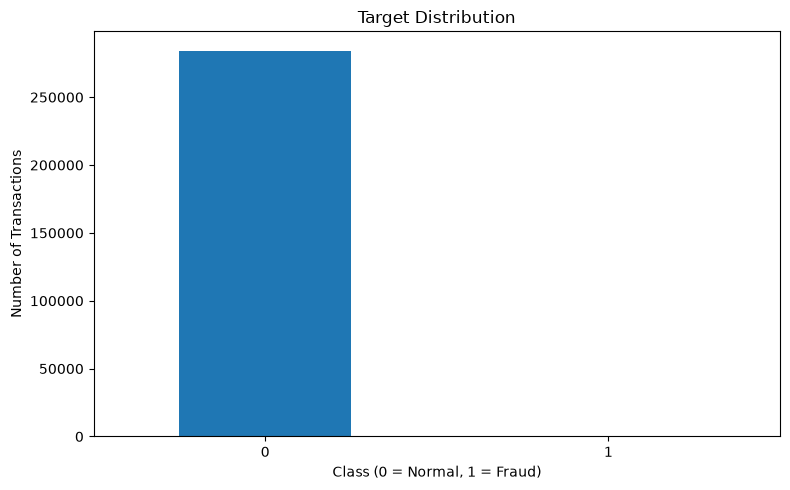

In [4]:
print("\nTarget Distribution:")
print(data["Class"].value_counts())

print("\nFraud Percentage:")
print(f"{data['Class'].mean() * 100:.3f}%")

plt.figure(figsize=(8, 5))
data["Class"].value_counts().sort_index().plot(kind="bar")
plt.title("Target Distribution")
plt.xlabel("Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Train/test split


In [5]:
X = data.drop("Class", axis=1)
y = data["Class"]

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Features Shape: (284807, 30)
Target Shape: (284807,)

Training Data Shape: (227845, 30)
Testing Data Shape: (56962, 30)


## Scaling and SMOTE



In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature Scaling Completed")

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("\nClass Distribution Before SMOTE:")
print(y_train.value_counts())

print("\nClass Distribution After SMOTE:")
print(y_train_smote.value_counts())


Feature Scaling Completed

Class Distribution Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

Class Distribution After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64


## Baseline model (k=5)



In [7]:
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_train_smote, y_train_smote)

y_pred = knn.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("\nKNN Model Results (k=5)")
print("Accuracy:", round(accuracy, 4))
print("F1-Score:", round(f1, 4))


KNN Model Results (k=5)
Accuracy: 0.9978
F1-Score: 0.5831


## Tuning k with cross-validation



In [8]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("knn", KNeighborsClassifier(n_jobs=-1))
])

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("\nBest k Value:")
print(grid_search.best_params_["knn__n_neighbors"])

print("\nBest Cross-Validation F1-Score:")
print(round(grid_search.best_score_, 4))

Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best k Value:
3

Best Cross-Validation F1-Score:
0.651


## Evaluate the tuned model



In [9]:
best_knn = grid_search.best_estimator_
y_pred_tuned = best_knn.predict(X_test)

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned, zero_division=0)

print("\nTuned KNN Model Results")
print("Accuracy:", round(accuracy_tuned, 4))
print("F1-Score:", round(f1_tuned, 4))


Tuned KNN Model Results
Accuracy: 0.9985
F1-Score: 0.6561


## Baseline vs. tuned

In [10]:
results = pd.DataFrame({
    "Model": ["KNN (k=5)", "Tuned KNN"],
    "Accuracy": [accuracy, accuracy_tuned],
    "F1-Score": [f1, f1_tuned]
})

print("\nModel Performance Comparison:")
print(results.to_string(index=False))


Model Performance Comparison:
    Model  Accuracy  F1-Score
KNN (k=5)  0.997841  0.583051
Tuned KNN  0.998473  0.656126


## Classification report and confusion matrix




Classification Report (Tuned KNN):
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.54      0.85      0.66        98

    accuracy                           1.00     56962
   macro avg       0.77      0.92      0.83     56962
weighted avg       1.00      1.00      1.00     56962


Confusion Matrix:
[[56792    72]
 [   15    83]]


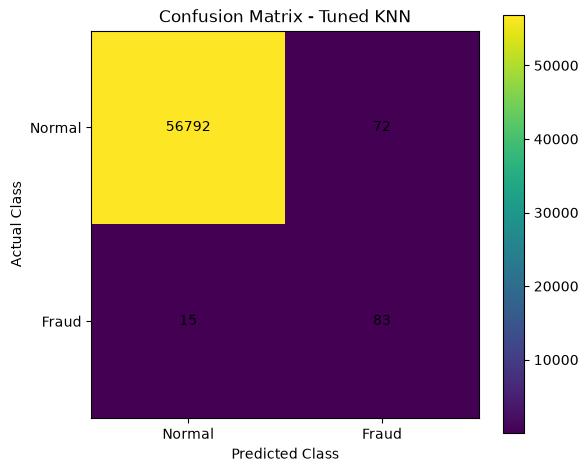

In [11]:
print("\nClassification Report (Tuned KNN):")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred_tuned)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix - Tuned KNN")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.yticks([0, 1], ["Normal", "Fraud"])
plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.show()

## Performance comparison chart

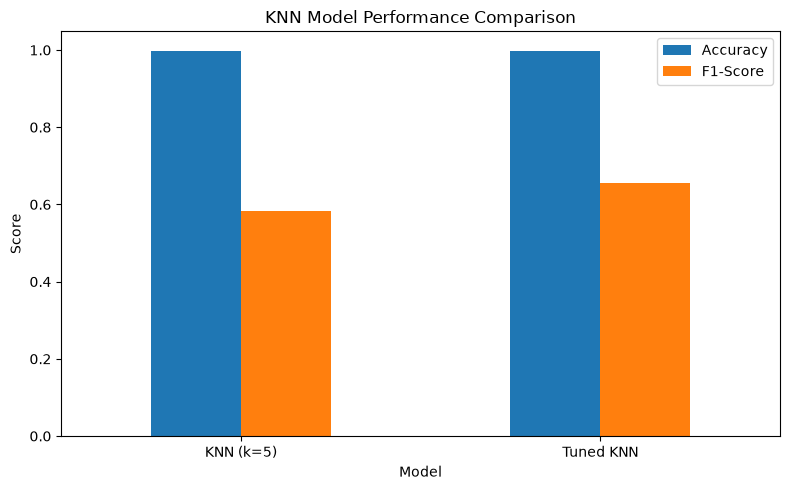

In [12]:
results.set_index("Model")[["Accuracy", "F1-Score"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("KNN Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()